# SC4020 Project 2 Task 3: Cold-Target Generalisation

**Problem.** The Task 2 CF predicts a target's score from that target's training scores. A *cold* target has none, so CF falls back to the ligand's mean score $\mu + b_u$. This is the same value for every new target so it is unable to tell new targets apart.

**Idea (guilt-by-association).** Task 1 (Step 4c) showed that targets with similar amino-acid sequences have similar binding profiles. Hence for a cold target we borrow scores from the **training targets whose sequences are most similar**. This keeps the lecture 11.3 prediction formula, but the neighbour similarity comes from the **sequence** which a new target has, instead of from scores which it does not have:

$$\hat r_{ui} = (\mu + b_u) + \frac{\sum_{j \in N_k(i;u)} s^{\text{seq}}_{ij}\,\big(r_{uj} - (\mu + b_u)\big)}{\sum_{j \in N_k(i;u)} s^{\text{seq}}_{ij}}$$

$N_k(i;u)$ = the $k$ training targets most similar in sequence to the cold target $i$ that ligand $u$ has a training score for. The target bias $b_i$ is unknown for a cold target, so the baseline part is the ligand mean $\mu + b_u$. The neighbours' deviations carry both their target bias and the ligand–target interaction.

**Sequence similarity: Jaccard on 3-mer sets (lecture 11.3).** Each protein is turned into the *set* of overlapping 3-letter fragments it contains (feature construction, lecture 12.2), e.g. `MKKF...` → {`MKK`, `KKF`, ...}. Two targets are similar if they share many fragments:

$$s^{\text{seq}}_{ij} = J(A_i, A_j) = \frac{|A_i \cap A_j|}{|A_i \cup A_j|}$$

This is the Jaccard similarity from lecture 11.3, applied to sequence fragments instead of rated items.

This requires `data/clean/` from `task1_analysis.ipynb`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kendalltau

SEED = 42
DATA_DIR = Path("data")
CLEAN_DIR = DATA_DIR / "clean"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

pairs = {n: pd.read_csv(CLEAN_DIR / f"{n}_pairs.csv", dtype={"ligand_key": str, "target_key": str})
         for n in ["davis", "kiba"]}
targets = {n: pd.read_csv(CLEAN_DIR / f"{n}_targets.csv", dtype=str).set_index("target_key")
           for n in ["davis", "kiba"]}
{n: (len(p), len(targets[n])) for n, p in pairs.items()}

{'davis': (25772, 379), 'kiba': (117657, 229)}

## Step 1: Cold-target split

Targets (not pairs) are split 70 / 15 / 15 with the shared seed. **All** pairs of a validation or test target are held out so these targets have no training scores at all. Validation targets are used to choose $k$, with test targets being evaluated once.

As Task 1 merged targets with identical sequences, a cold target can never have an exact sequence copy in training (otherwise the task would be trivial).

In [2]:
from project2_cold import cold_target_split

splits, roles, rows = {}, {}, []
for name, df in pairs.items():
    splits[name], roles[name], dropped = cold_target_split(df)
    s = splits[name]
    for part in ["train", "val", "test"]:
        assert part == "train" or not s.loc[s["split"] == part, "target_key"].isin(
            s.loc[s["split"] == "train", "target_key"]).any()          # cold: no overlap of targets
    rows.append({"dataset": name.upper(),
                 **{f"{p} targets": int((pd.Series(roles[name]) == p).sum()) for p in ["train", "val", "test"]},
                 **{f"{p} pairs": int((s["split"] == p).sum()) for p in ["train", "val", "test"]},
                 "dropped (ligand unseen)": dropped})
pd.DataFrame(rows).set_index("dataset")

,train targets,val targets,test targets,train pairs,val pairs,test pairs,dropped (ligand unseen)
dataset,,,,,,,
DAVIS,265,56,58,18020,3808,3944,0
KIBA,160,34,35,80374,16800,20483,0


## Step 2: Target–target sequence similarity

**Jaccard on 3-mer sets.** Each sequence becomes the set of its overlapping 3-letter fragments. Sets are stored as a 0/1 matrix (one column per fragment that occurs anywhere), so $|A_i \cap A_j|$ is a matrix product and $|A_i \cup A_j| = |A_i| + |A_j| - |A_i \cap A_j|$.

The similarity uses no binding scores, so there is no label leakage and it can be computed for any brand-new target

In [3]:
from project2_cold import sequence_similarity, kmer_set

def jaccard_similarity(name, k=3):
    return sequence_similarity(targets[name], k)

MAIN = "Jaccard 3-mer"
similarities = {name: {MAIN: jaccard_similarity(name)} for name in pairs}


## Step 3: Models

- **global mean** $\mu$
- **CF fallback** $\mu + b_u$: what the Task 2 CF predicts for a cold target (lecture baseline without $b_i$). It has the same score for every cold target of a ligand, so it cannot rank them
- **sequence neighbours** (formula above) with Jaccard similarity.

$\mu$ and $b_u = \bar r_u - \mu$ come from training pairs only. Only positive similarities are used. If a ligand has no positively similar training target, the prediction falls back to $\mu + b_u$.

In [4]:
from project2_cold import fit, predict


## Step 4: Metrics

The same shared metrics as Task 2 are used. Hit@1/5 and the rank of the first truly best target are **expectations over uniform tie breaking**, so equal predictions never receive an artificial ranking from file order. Tied true best targets are all considered correct. Ligands whose true scores are all equal are excluded from ranking and macro CI, and their count is reported.

**Pooled CI** compares every pair of observations, including observations belonging to different ligands. **Macro CI** first calculates CI within each rankable ligand, then averages across ligands. The latter directly asks whether a method can distinguish a ligand's cold targets; the ligand-mean fallback has macro CI 0.5.


In [5]:
from project2_metrics import concordance_index, ranking_metrics, summarize_predictions

def evaluate(df, pred, n_used=None):
    out = summarize_predictions(df.assign(pred=pred))
    if n_used is not None:
        out["fallback %"] = 100 * np.mean(n_used == 0)
    return out


## Step 5: Choose $k$ on the cold validation targets

In [6]:
KS = [1, 2, 3, 5, 10, 20, 40]
models, best_k, search = {}, {}, []
for name, df in splits.items():
    models[name] = fit(df[df["split"] == "train"])
    val = df[df["split"] == "val"]
    best_k[name] = {}
    for sname, S in similarities[name].items():
        scores = {}
        for k in KS:
            pred, _ = predict(models[name], val, "neighbours", S, k)
            scores[k] = np.mean((val["score"].values - pred) ** 2)
            search.append({"dataset": name.upper(), "similarity": sname, "k": k, "val MSE": scores[k]})
        best_k[name][sname] = min(scores, key=scores.get)
    print(name.upper(), "best k:", best_k[name])

search_df = pd.DataFrame(search)
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, name in zip(axes, splits):
    for sname, g in search_df[search_df["dataset"] == name.upper()].groupby("similarity"):
        ax.plot(g["k"], g["val MSE"], marker="o", label=sname)
    fb, _ = predict(models[name], splits[name][splits[name]["split"] == "val"], "fallback")
    v = splits[name][splits[name]["split"] == "val"]["score"].values
    ax.axhline(np.mean((v - fb) ** 2), color="grey", linestyle="--", label="CF fallback (mu + b_u)")
    ax.set_xscale("log")
    ax.set_xlabel("Number of sequence neighbours k")
    ax.set_ylabel("Validation MSE (cold targets)")
    ax.set_title(name.upper())
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "cold_target_k_search.png", dpi=200)
plt.show()

DAVIS best k: {'Jaccard 3-mer': 5}


KIBA best k: {'Jaccard 3-mer': 3}


C:\Users\ROG\AppData\Local\Temp\ipykernel_17796\670741698.py:31: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Step 6: Original method on the cold test targets

The original sequence-neighbour configuration is selected using validation MSE, then evaluated below. This preserves the original experiment as a comparator. The extension later in this notebook was motivated by the original test error analysis, so it is explicitly exploratory; its parameters are never selected using test labels.


In [7]:
results, scored_test = [], {}
for name, df in splits.items():
    test = df[df["split"] == "test"]
    m = models[name]
    for label, method, S, k in [("global mean", "global", None, None),
                                ("CF fallback (mu + b_u)", "fallback", None, None)] + \
                               [(f"neighbours: {s}, k={best_k[name][s]}", "neighbours", Sm, best_k[name][s])
                                for s, Sm in similarities[name].items()]:
        pred, n_used = predict(m, test, method, S, k) if method == "neighbours" else predict(m, test, method)
        results.append({"dataset": name.upper(), "model": label,
                        **evaluate(test, pred, n_used if method == "neighbours" else None)})
        if method == "neighbours":
            scored_test[(name, label)] = test.assign(pred=pred)

results_df = pd.DataFrame(results).set_index(["dataset", "model"])
results_df.round(4)

MSE      CI  macro CI   Hit@1  \
dataset model                                                              
DAVIS   global mean                     0.6525  0.5000    0.5000  0.0175   
        CF fallback (mu + b_u)          0.4597  0.7842    0.5000  0.0175   
        neighbours: Jaccard 3-mer, k=5  0.2926  0.8435    0.7594  0.4848   
KIBA    global mean                     0.7070  0.5000    0.5000  0.1413   
        CF fallback (mu + b_u)          0.3944  0.7157    0.5000  0.1413   
        neighbours: Jaccard 3-mer, k=3  0.3647  0.7478    0.6133  0.3510   

                                         Hit@5  random Hit@1  random Hit@5  \
dataset model                                                                
DAVIS   global mean                     0.0874        0.0175        0.0874   
        CF fallback (mu + b_u)          0.0874        0.0175        0.0874   
        neighbours: Jaccard 3-mer, k=5  0.6380        0.0175        0.0874   
KIBA    global mean                     0.5376        0.1413        0.5376   
        CF fallback (mu + b_u)          0.5376        0.1413        0.5376   
        neighbours: Jaccard 3-mer, k=3  0.7693        0.1413        0.5376   

                                        mean rank of best  ranked ligands  \
dataset model                                                               
DAVIS   global mean                               29.3510              66   
        CF fallback (mu + b_u)                    29.3510              66   
        neighbours: Jaccard 3-mer, k=5             8.1818              66   
KIBA    global mean                                6.9129            1401   
        CF fallback (mu + b_u)                     6.9129            1401   
        neighbours: Jaccard 3-mer, k=3             4.0297            1401   

                                        excluded ligands  fallback %  
dataset model                                                         
DAVIS   global mean                                    2         NaN  
        CF fallback (mu + b_u)                         2         NaN  
        neighbours: Jaccard 3-mer, k=5                 2         0.0  
KIBA    global mean                                  454         NaN  
        CF fallback (mu + b_u)                       454         NaN  
        neighbours: Jaccard 3-mer, k=3               454         0.0

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(15, 9))
plot_df = results_df.reset_index()
plot_df["short"] = plot_df["model"].str.replace("neighbours: ", "").str.replace(r", k=\d+", "", regex=True)
for ax, metric in zip(axes, ["MSE", "CI", "Hit@5"]):
    p = plot_df.pivot(index="dataset", columns="short", values=metric)
    p.plot(kind="bar", ax=ax, rot=0, legend=(metric == "MSE"))
    ax.set_title(f"Cold test targets: {metric}" + (" (lower is better)" if metric == "MSE" else ""))
    ax.set_xlabel("")
if axes[0].get_legend():
    axes[0].legend(fontsize=7)
plt.tight_layout()
plt.savefig(FIG_DIR / "cold_target_results.png", dpi=200)
plt.show()

C:\Users\ROG\AppData\Local\Temp\ipykernel_17796\200167088.py:13: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Step 7: When does it work? Error by target relatedness

Each cold test target is grouped by its similarity to the nearest training target. This reproduces the original diagnostic. A globally similar training target may have **no measured score for a particular KIBA ligand**; the extension therefore bases its confidence on neighbours actually observed for that ligand. The zero-similarity boundary is included in the first bin.


In [9]:
rows = []
for name, df in splits.items():
    S = similarities[name][MAIN]
    label = f"neighbours: {MAIN}, k={best_k[name][MAIN]}"
    t = scored_test[(name, label)].copy()
    train_tgts = [k for k, r in roles[name].items() if r == "train"]
    nearest = S.loc[:, train_tgts].max(axis=1)
    t["nearest train similarity"] = pd.cut(t["target_key"].map(nearest), [-1e-12, 0.15, 0.25, 0.4, 1.0], include_lowest=True)
    fb, _ = predict(models[name], t, "fallback")
    t["fallback"] = fb
    for b, g in t.groupby("nearest train similarity", observed=True):
        rows.append({"dataset": name.upper(), "nearest-train similarity": str(b),
                     "cold targets": g["target_key"].nunique(), "test pairs": len(g),
                     "neighbours MSE": np.mean((g["score"] - g["pred"]) ** 2),
                     "fallback MSE": np.mean((g["score"] - g["fallback"]) ** 2)})
rel_df = pd.DataFrame(rows)
rel_df["MSE reduction %"] = 100 * (1 - rel_df["neighbours MSE"] / rel_df["fallback MSE"])
rel_df.round(3)

,dataset,nearest-train similarity,cold targets,test pairs,neighbours MSE,fallback MSE,MSE reduction %
0,DAVIS,"(-0.001000000001, 0.15]",24,1632,0.343,0.328,-4.509
1,DAVIS,"(0.15, 0.25]",16,1088,0.386,0.770,49.848
2,DAVIS,"(0.25, 0.4]",9,612,0.178,0.406,56.051
3,DAVIS,"(0.4, 1.0]",9,612,0.107,0.313,65.925
4,KIBA,"(-0.001000000001, 0.15]",12,7144,0.411,0.310,-32.740
5,KIBA,"(0.15, 0.25]",13,8139,0.355,0.410,13.398
6,KIBA,"(0.25, 0.4]",5,2870,0.240,0.351,31.536
7,KIBA,"(0.4, 1.0]",5,2330,0.407,0.652,37.478


## Step 8: Confidence-dependent shrinkage

The original error analysis showed that sequence neighbours can hurt when relatedness is low. We test the estimate

$$\hat r = b_u + \alpha(s) (\hat r_{\mathrm{sequence}} - b_u), \qquad \alpha(s)=\mathrm{clip}((s-l)/(h-l),0,1),$$

where $b_u$ here denotes the ligand's **mean training score**, and $s$ is the largest sequence similarity among targets actually measured for that ligand in training. Low confidence moves the prediction toward the ligand mean. This is a heuristic confidence score, not a calibrated probability.

The comparison includes the original neighbour method, the fallback, a constant-weight shrinkage ablation, and similarity-dependent shrinkage. For each split, $k$ and all shrinkage settings are selected by **validation MSE only** using the fixed grids in `project2_cold.py`. The original test analysis motivated the hypothesis; additional seeds assess robustness and do not turn this into an untouched external evaluation.

Run `python project2_cold.py` to regenerate the experiment tables below for seeds 42, 7 and 2026. These outputs are loaded rather than repeating the complete multi-seed experiment on every notebook run.


In [10]:
COLD_RESULTS = Path("results/cold")
required = ["selected_parameters.csv", "test_metrics.csv", "paired_bootstrap.csv"]
if all((COLD_RESULTS / name).exists() for name in required):
    tuned = pd.read_csv(COLD_RESULTS / "selected_parameters.csv")
    extended = pd.read_csv(COLD_RESULTS / "test_metrics.csv")
    intervals = pd.read_csv(COLD_RESULTS / "paired_bootstrap.csv")
    display(tuned[tuned["seed"] == SEED].round(4))
    display(extended[extended["seed"] == SEED].set_index(["dataset", "method"])[
        ["MSE", "CI", "macro CI", "Hit@1", "Hit@5", "excluded ligands"]].round(4))
    display(intervals[(intervals["seed"] == SEED) &
                      (intervals["cluster"] == "target_key") &
                      (intervals["model"] == "similarity_shrinkage")][
        ["dataset", "model", "reference", "estimate", "delta", "delta_ci_low", "delta_ci_high", "n_clusters"]].round(4))
else:
    print("Extended experiments have not been generated. Run: python project2_cold.py")


,dataset,seed,method,k,alpha,low,high,val_MSE
0,davis,42,neighbours,5,1.0,0.0,1.0,0.3201
1,davis,42,global_shrinkage,2,0.5,0.0,1.0,0.2980
2,davis,42,similarity_shrinkage,2,1.0,0.0,0.3,0.2804
9,kiba,42,neighbours,3,1.0,0.0,1.0,0.3877
10,kiba,42,global_shrinkage,1,0.5,0.0,1.0,0.3610
11,kiba,42,similarity_shrinkage,2,1.0,0.0,0.3,0.3382


MSE      CI  macro CI   Hit@1   Hit@5  \
dataset method                                                           
davis   global                0.6525  0.5000    0.5000  0.0175  0.0874   
        fallback              0.4597  0.7842    0.5000  0.0175  0.0874   
        neighbours            0.2926  0.8435    0.7594  0.4848  0.6380   
        global_shrinkage      0.2989  0.8550    0.7492  0.4697  0.6997   
        similarity_shrinkage  0.2687  0.8575    0.7648  0.4697  0.6667   
kiba    global                0.7070  0.5000    0.5000  0.1413  0.5376   
        fallback              0.3944  0.7157    0.5000  0.1413  0.5376   
        neighbours            0.3647  0.7478    0.6133  0.3510  0.7693   
        global_shrinkage      0.3421  0.7413    0.5947  0.2778  0.7372   
        similarity_shrinkage  0.3028  0.7621    0.6214  0.3355  0.7659   

                              excluded ligands  
dataset method                                  
davis   global                               2  
        fallback                             2  
        neighbours                           2  
        global_shrinkage                     2  
        similarity_shrinkage                 2  
kiba    global                             454  
        fallback                           454  
        neighbours                         454  
        global_shrinkage                   454  
        similarity_shrinkage               454

,dataset,model,reference,estimate,delta,delta_ci_low,delta_ci_high,n_clusters
3,davis,similarity_shrinkage,neighbours,0.2687,-0.0239,-0.0455,-0.0026,58
15,kiba,similarity_shrinkage,neighbours,0.3028,-0.0619,-0.1035,-0.0255,35


## Step 9: Robustness and uncertainty

The extension was motivated by the seed-42 test analysis above, so a single split cannot confirm it. Seeds **42, 7 and 2026** each get their own cold-target split and their own validation search; every split's result is reported, not the best one.

The MSE uncertainty intervals resample **whole cold targets**, retaining all measurements of each sampled target. Intervals are paired across methods and conditional on the fitted model and split; they do not include all possible training uncertainty. A negative MSE difference favours the extension. An interval crossing zero does not establish an improvement.


MSE         macro CI           Hit@1          \
                                mean     std     mean     std    mean     std   
dataset method                                                                  
davis   fallback              0.4522  0.0378   0.5000  0.0000  0.0174  0.0002   
        global                0.6348  0.0470   0.5000  0.0000  0.0174  0.0002   
        global_shrinkage      0.2966  0.0145   0.7543  0.0171  0.3829  0.1005   
        neighbours            0.3024  0.0276   0.7554  0.0203  0.3879  0.1072   
        similarity_shrinkage  0.2628  0.0171   0.7632  0.0126  0.3878  0.0834   
kiba    fallback              0.3920  0.0076   0.5000  0.0000  0.1817  0.0360   
        global                0.7051  0.0253   0.5000  0.0000  0.1817  0.0360   
        global_shrinkage      0.3234  0.0303   0.6139  0.0275  0.3513  0.0696   
        neighbours            0.3388  0.0352   0.6287  0.0194  0.3847  0.0311   
        similarity_shrinkage  0.3016  0.0181   0.6223  0.0152  0.3784  0.0463   

                               Hit@5          
                                mean     std  
dataset method                                
davis   fallback              0.0870  0.0007  
        global                0.0870  0.0007  
        global_shrinkage      0.6956  0.0565  
        neighbours            0.6649  0.0754  
        similarity_shrinkage  0.6791  0.0502  
kiba    fallback              0.5905  0.0462  
        global                0.5905  0.0462  
        global_shrinkage      0.7677  0.0481  
        neighbours            0.7851  0.0319  
        similarity_shrinkage  0.7758  0.0487

method        fallback  global  global_shrinkage  neighbours  \
dataset seed                                                   
davis   7       0.4856  0.6704            0.2811      0.2811   
        42      0.4597  0.6525            0.2989      0.2926   
        2026    0.4112  0.5814            0.3099      0.3335   
kiba    7       0.3980  0.7294            0.2885      0.2987   
        42      0.3944  0.7070            0.3421      0.3647   
        2026    0.3835  0.6789            0.3396      0.3530   

method        similarity_shrinkage  similarity minus original  \
dataset seed                                                    
davis   7                   0.2435                    -0.0376   
        42                  0.2687                    -0.0239   
        2026                0.2761                    -0.0574   
kiba    7                   0.2829                    -0.0158   
        42                  0.3028                    -0.0619   
        2026                0.3190                    -0.0340   

method        similarity minus global shrinkage  
dataset seed                                     
davis   7                               -0.0376  
        42                              -0.0302  
        2026                            -0.0338  
kiba    7                               -0.0056  
        42                              -0.0393  
        2026                            -0.0206

DAVIS: similarity shrinkage improves MSE on 3/3 splits; mean change versus original = -0.0396.
KIBA: similarity shrinkage improves MSE on 3/3 splits; mean change versus original = -0.0372.


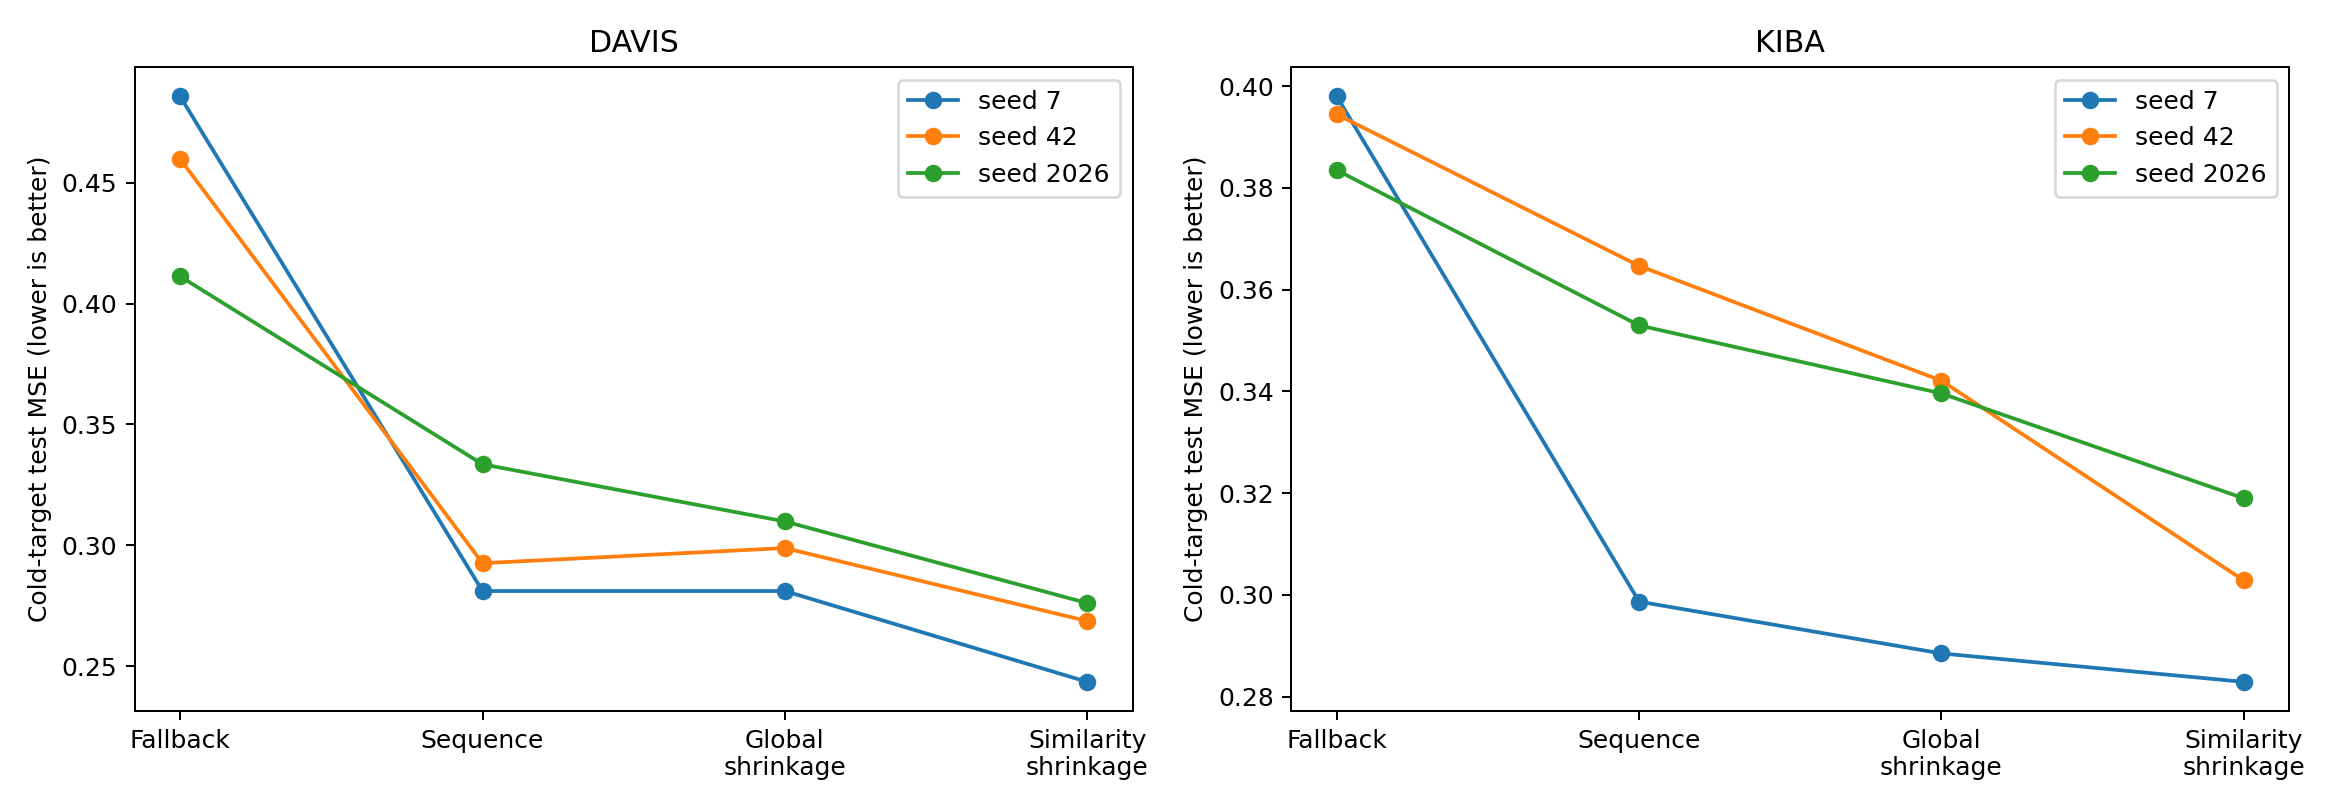

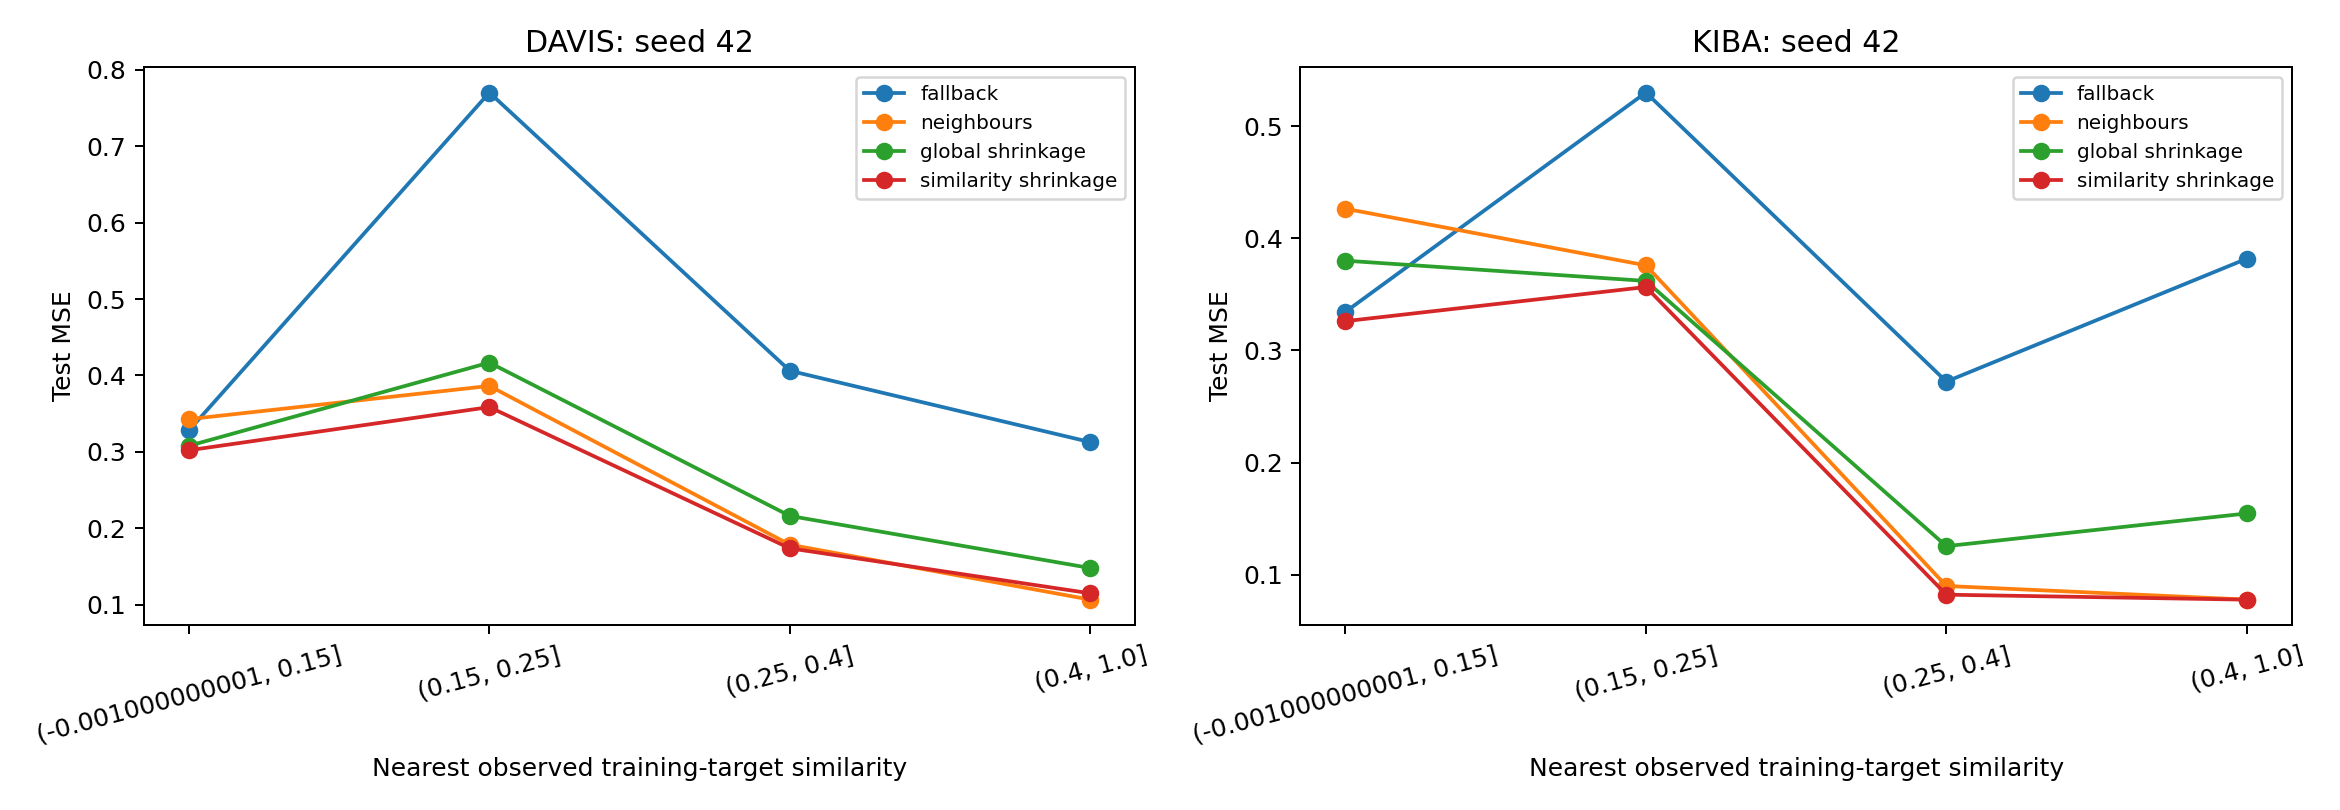

In [11]:
if (COLD_RESULTS / "test_metrics.csv").exists():
    extended = pd.read_csv(COLD_RESULTS / "test_metrics.csv")
    display(extended.groupby(["dataset", "method"])[["MSE", "macro CI", "Hit@1", "Hit@5"]].agg(["mean", "std"]).round(4))
    comparison = extended.pivot(index=["dataset", "seed"], columns="method", values="MSE")
    comparison["similarity minus original"] = comparison["similarity_shrinkage"] - comparison["neighbours"]
    comparison["similarity minus global shrinkage"] = comparison["similarity_shrinkage"] - comparison["global_shrinkage"]
    display(comparison.round(4))
    for dataset, values in comparison.groupby(level="dataset"):
        wins = int((values["similarity minus original"] < 0).sum())
        print(f"{dataset.upper()}: similarity shrinkage improves MSE on {wins}/{len(values)} splits; "
              f"mean change versus original = {values['similarity minus original'].mean():+.4f}.")
    from IPython.display import Image
    for filename in ["cold_robustness.png", "cold_similarity_bands.png"]:
        if (FIG_DIR / filename).exists():
            display(Image(filename=str(FIG_DIR / filename)))


## Step 10: Predict a newly supplied protein sequence

The saved cold-target checkpoint contains training affinities, training protein sequences, score scale, seed and selected settings. `predict_new_target` computes similarities for a supplied amino-acid string; the target does not need to exist in the model's ID table. It rejects unsupported ligand IDs because cold-ligand prediction is outside this experiment.

The demonstration supplies the sequence of a held-out target as if it were newly provided. No affinity labels are passed to the prediction function. Separate automated checks compare this interface and reloaded checkpoints with batch predictions.


In [12]:
from project2_cold import predict_new_target

for dataset in ["davis", "kiba"]:
    checkpoint = Path("saved_models") / f"{dataset}_cold.npz"
    if not checkpoint.exists():
        print(f"{dataset.upper()}: run python project2_cold.py to generate the cold-target checkpoint.")
        continue
    held_out = splits[dataset].loc[splits[dataset]["split"] == "test"]
    target_id = held_out.iloc[0]["target_key"]
    ligand_ids = held_out.loc[held_out["target_key"] == target_id, "ligand_key"].head(3).tolist()
    supplied_sequence = targets[dataset].loc[target_id, "sequence"]
    print(f"{dataset.upper()}: new sequence from held-out target {target_id}")
    display(predict_new_target(checkpoint, supplied_sequence, ligand_ids).round(4))

if (COLD_RESULTS / "reload_checks.csv").exists():
    display(pd.read_csv(COLD_RESULTS / "reload_checks.csv"))


DAVIS: new sequence from held-out target ACVR2B


,ligand_key,prediction,fallback,n_neighbours,nearest_observed_similarity,confidence_weight
0,11314340,5.3724,5.4697,2,0.093,0.3098
1,24889392,5.0976,5.1414,2,0.093,0.3098
2,11409972,6.0422,5.9788,2,0.093,0.3098


KIBA: new sequence from held-out target O14920


,ligand_key,prediction,fallback,n_neighbours,nearest_observed_similarity,confidence_weight
0,CHEMBL1087421,11.1315,11.1733,2,0.1710,0.5699
1,CHEMBL1088633,11.1215,11.1500,2,0.1710,0.5699
2,CHEMBL1788116,11.4445,11.5827,2,0.0859,0.2862


,dataset,seed,checkpoint,reload_max_absolute_error,new_sequence_max_absolute_error
0,davis,42,saved_models\davis_cold.npz,0.0,0.0
1,kiba,42,saved_models\kiba_cold.npz,0.0,0.0


The extension tests a specific failure mechanism instead of assuming that more complex predictions always help. Its usefulness must be judged against both the unmodified sequence method and constant shrinkage, on overall errors, low-similarity cases and ranking metrics.
